<a href="https://colab.research.google.com/github/Ambesh246/Prompt_Quality_Analyzer/blob/ML_prompt/Prompt_Quality_Analyzer_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prompt Quality Analyzer — Machine Learning Project

**Goal:** take a prompt written by a user, estimate its quality on a 0–100 scale, point out possible gaps, and build a clearer version of the same request.

This notebook is written as a step-by-step student project: first understand the data, then explore it, build features, train a model, evaluate it, and finally use it on a new prompt.


## 1. Problem statement and approach

A prompt can be difficult to answer when the task is unclear, important context is missing, constraints are vague, or the expected response format is not stated. The analyzer tries to identify these signals before the prompt is used.

**ML framing:** supervised regression. Each training example contains prompt text and a normalized quality label. We train a model to predict that label.

**Why a hybrid approach?** TF-IDF features capture words and short phrases, while manually designed features capture structure (for example, whether a prompt mentions an audience, examples, or an output format). A Ridge regression model combines both. The advice generator then uses simple checks, so it can explain why it suggests a change.

**Dataset source:** [agentlans/prompt-quality on Hugging Face](https://huggingface.co/datasets/agentlans/prompt-quality). Its dataset page lists a CC BY 4.0 license and contains prompt text, normalized quality scores, and assessments from multiple models. We will keep the experiment small enough for a typical free Colab runtime.

## 2. Install and import libraries


In [1]:
!pip -q install datasets

In [2]:
import re
import string
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the public dataset



In [28]:
DATASET_ID = "agentlans/prompt-quality"
MAX_SAMPLES= 75000
raw_dataset = load_dataset(DATASET_ID, split="train")
df = raw_dataset.to_pandas()
print("Full dataset shape:", df.shape)
print("Available columns:", df.columns.tolist())
display(df.head(5))

Full dataset shape: (79806, 11)
Available columns: ['prompt', 'quality', 'transformed_quality', 'allenai-olmo-3-7b-instruct', 'google-gemma-3-12b-it', 'ibm-granite-granite-4-0-h-tiny', 'meta-llama-llama-3-1-8b-instruct', 'microsoft-phi-4', 'nvidia-nvidia-nemotron-nano-9b-v2', 'qwen-qwen3-8b', 'tiiuae-falcon-h1-7b-instruct']


,prompt,quality,transformed_quality,allenai-olmo-3-7b-instruct,google-gemma-3-12b-it,ibm-granite-granite-4-0-h-tiny,meta-llama-llama-3-1-8b-instruct,microsoft-phi-4,nvidia-nvidia-nemotron-nano-9b-v2,qwen-qwen3-8b,tiiuae-falcon-h1-7b-instruct
0,NAME_1 NAME_2 is the best anti virus for windows,-4.86366,0.00766,3.0,2.0,3.0,2.0,2.0,2.0,2,2.0
1,"Trace the evolution of children's books, exami...",0.92516,0.71609,3.0,5.0,4.0,5.0,5.0,5.0,5,4.0
2,its the relation between my father and me is a...,-3.83303,0.02119,3.0,3.0,3.0,3.0,3.0,2.0,2,2.0
3,"[QUESTION] Given the sentence ""Two men in colo...",-0.76970,0.31654,NaN,4.0,NaN,5.0,2.0,3.0,5,NaN
4,"A car rental company has a fleet of 1,000 vehi...",2.45391,0.92085,5.0,5.0,6.0,5.0,6.0,5.0,5,5.0


## 4. Select columns and clean the data

In [29]:
required_columns = {"prompt", "transformed_quality"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Dataset columns not found: {missing_columns}. Check the dataset card.")

model_df = df[["prompt", "transformed_quality"]].copy()
model_df["prompt"] = model_df["prompt"].fillna("").astype(str).str.strip()
model_df["transformed_quality"] = pd.to_numeric(
    model_df["transformed_quality"], errors="coerce"
)

model_df = model_df[
    (model_df["prompt"].str.len() > 0) &
    model_df["transformed_quality"].notna()
].copy()
model_df = model_df.drop_duplicates(subset="prompt")
model_df["target_score"] = model_df["transformed_quality"].clip(0, 1) * 100

if len(model_df) > MAX_SAMPLES:
    model_df = model_df.sample(n=MAX_SAMPLES, random_state=RANDOM_STATE)

model_df = model_df.reset_index(drop=True)
print("Rows used in this experiment:", len(model_df))
print("Blank prompts remaining:", int((model_df["prompt"].str.len() == 0).sum()))
print("Duplicate prompts remaining:", int(model_df["prompt"].duplicated().sum()))
display(model_df[["prompt", "target_score"]].head())

Rows used in this experiment: 75000
Blank prompts remaining: 0
Duplicate prompts remaining: 0


,prompt,target_score
0,List six constellations visible in the night s...,94.442
1,"Translate ""Only Facts In 2012 the exhibition p...",75.731
2,Give me code in-aframe that uses the charts co...,19.828
3,Read the following article and select the best...,76.197
4,Will 4oz of solid she's butter melted fit in 1...,12.401


## 5. Explore the data (EDA)


In [31]:
model_df["word_count"] = model_df["prompt"].apply(lambda text: len(text.split()))


In [32]:
print("Prompt length summary:")
display(model_df["word_count"].describe().to_frame())

Prompt length summary:


,word_count
count,75000.000000
mean,104.605213
std,231.696129
min,1.000000
25%,14.000000
50%,39.000000
75%,94.000000
max,6322.000000


In [34]:
print("Target score summary:")
display(model_df["target_score"].describe().to_frame())

Target score summary:


,target_score
count,75000.000000
mean,52.175705
std,32.511832
min,0.043000
25%,20.214000
50%,56.332500
75%,83.754000
max,99.317000


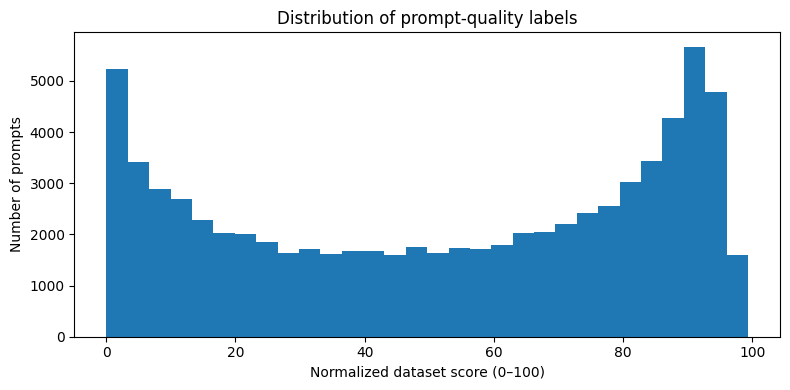

In [35]:
plt.figure(figsize=(8, 4))
plt.hist(model_df["target_score"], bins=30)
plt.title("Distribution of prompt-quality labels")
plt.xlabel("Normalized dataset score (0–100)")
plt.ylabel("Number of prompts")
plt.tight_layout()
plt.show()


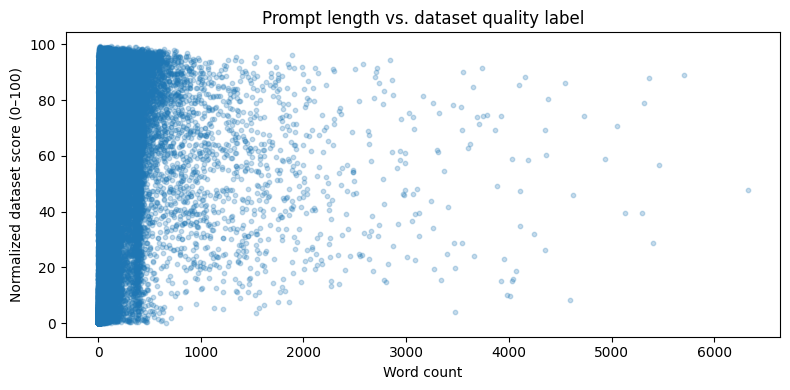

In [36]:
plt.figure(figsize=(8, 4))
plt.scatter(model_df["word_count"], model_df["target_score"], alpha=0.25, s=10)
plt.title("Prompt length vs. dataset quality label")
plt.xlabel("Word count")
plt.ylabel("Normalized dataset score (0–100)")
plt.tight_layout()
plt.show()

## 6. Create structural features

In [37]:
def extract_structural_features(texts):
    rows = []

    for value in texts:
        text = str(value)
        lower = text.lower()
        words = re.findall(r"\b[\w'-]+\b", lower)
        word_count = len(words)
        char_count = len(text)
        sentences = [part for part in re.split(r"[.!?]+", text) if part.strip()]
        unique_ratio = len(set(words)) / max(word_count, 1)

        def contains_any(phrases):
            return int(any(phrase in lower for phrase in phrases))

        rows.append([
            np.log1p(char_count),
            np.log1p(word_count),
            np.mean([len(word) for word in words]) if words else 0.0,
            unique_ratio,
            np.log1p(len(sentences)),
            np.log1p(text.count("?")),
            np.log1p(text.count("!")),
            np.log1p(text.count("\n")),
            sum(char.isdigit() for char in text) / max(char_count, 1),
            sum(char in string.punctuation for char in text) / max(char_count, 1),
            contains_any(["- ", "* ", "1.", "1)", "•"]),
            contains_any(["step-by-step", "step by step", "first", "then", "finally", "procedure"]),
            contains_any(["json", "markdown", "table", "bullet points", "format", "csv", "headings", "list of"]),
            contains_any(["you are", "act as", "as an expert", "as a professional"]),
            contains_any(["context", "background", "based on", "given the following", "here is", "input:"]),
            contains_any(["must", "should", "do not", "don't", "avoid", "limit", "maximum", "minimum", "within", "only"]),
            contains_any(["example", "for example", "sample", "illustration", "e.g."]),
            contains_any(["audience", "for beginners", "for experts", "for a student", "for children", "for managers"]),
            contains_any(["write", "create", "explain", "summarize", "compare", "analyze", "analyse", "generate", "design", "build", "calculate", "classify", "translate", "debug", "recommend", "plan"]),
        ])

    return np.asarray(rows, dtype=float)

STRUCTURE_FEATURE_NAMES = [
    "log_char_count", "log_word_count", "average_word_length", "unique_word_ratio",
    "log_sentence_count", "log_question_marks", "log_exclamation_marks", "log_line_breaks",
    "digit_ratio", "punctuation_ratio", "has_bullets_or_numbering", "mentions_steps",
    "mentions_output_format", "mentions_role", "mentions_context", "mentions_constraints",
    "mentions_example", "mentions_audience", "contains_task_verb"
]

feature_demo = extract_structural_features(model_df["prompt"].head(5))
feature_demo_df = pd.DataFrame(feature_demo, columns=STRUCTURE_FEATURE_NAMES)
display(pd.concat([model_df[["prompt"]].head(5).reset_index(drop=True), feature_demo_df], axis=1))

,prompt,log_char_count,log_word_count,average_word_length,unique_word_ratio,log_sentence_count,log_question_marks,log_exclamation_marks,log_line_breaks,digit_ratio,punctuation_ratio,has_bullets_or_numbering,mentions_steps,mentions_output_format,mentions_role,mentions_context,mentions_constraints,mentions_example,mentions_audience,contains_task_verb
0,List six constellations visible in the night s...,4.836282,2.995732,5.526316,0.894737,0.693147,0.000000,0.0,0.000000,0.000000,0.016000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,"Translate ""Only Facts In 2012 the exhibition p...",5.883322,3.850148,6.478261,0.869565,1.098612,0.693147,0.0,0.000000,0.019553,0.041899,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,Give me code in-aframe that uses the charts co...,4.644391,2.890372,4.941176,1.000000,0.693147,0.000000,0.0,0.000000,0.000000,0.038835,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,Read the following article and select the best...,6.572283,4.962845,3.788732,0.542254,2.944439,0.000000,0.0,0.693147,0.000000,0.042017,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Will 4oz of solid she's butter melted fit in 1...,4.025352,2.564949,3.583333,1.000000,1.098612,0.693147,0.0,0.000000,0.054545,0.054545,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 7. Train/test split


In [38]:
X = model_df["prompt"].to_numpy()
y = model_df["target_score"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Training prompts: {len(X_train):,}")
print(f"Testing prompts:  {len(X_test):,}")

Training prompts: 60,000
Testing prompts:  15,000


## 8. Establish a simple baseline

A useful model should beat a simple baseline. Here the baseline always predicts the mean quality label from the training data. Later we compare the ML model against it using MAE, RMSE, and R².

In [39]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_predictions = baseline.predict(np.zeros((len(y_test), 1)))

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print(f"Baseline MAE:  {baseline_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")
print(f"Baseline R²:   {baseline_r2:.3f}")

Baseline MAE:  29.16
Baseline RMSE: 32.50
Baseline R²:   -0.000


## 9. Build the ML model

The model combines three feature groups:

- **Word TF-IDF:** informative words and two-word phrases.
- **Character TF-IDF:** spelling and character-pattern information.
- **Structural features:** readable signals we engineered in the earlier cell.

Ridge regression is a regularized linear model. It is a practical first choice for sparse text features because it is comparatively fast and keeps the pipeline easy to inspect. This is not a fine-tuned large language model.

In [40]:
def make_feature_union():
    return FeatureUnion([
        ("word_tfidf", TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_features=10_000,
            sublinear_tf=True,
        )),
        ("char_tfidf", TfidfVectorizer(
            analyzer="char",
            lowercase=True,
            ngram_range=(3, 5),
            min_df=3,
            max_features=5_000,
            sublinear_tf=True,
        )),
        ("structure", Pipeline([
            ("extract", FunctionTransformer(extract_structural_features, validate=False)),
            ("scale", StandardScaler()),
        ])),
    ])

prompt_model = Pipeline([
    ("features", make_feature_union()),
    ("regressor", Ridge(alpha=2.0)),
])

prompt_model.fit(X_train, y_train)
print("Training complete.")

Training complete.


## 10. Evaluate on the held-out test set

- **MAE:** average absolute prediction error in score points. Lower is better.
- **RMSE:** like MAE, but penalizes larger errors more. Lower is better.
- **R²:** compares the model with a constant-mean prediction. Higher is better; it can be negative if the model is worse than that baseline.

Report the actual values produced by your run. Do not put a made-up accuracy number in the evaluation.

In [41]:
test_predictions = np.clip(prompt_model.predict(X_test), 0, 100)

model_mae = mean_absolute_error(y_test, test_predictions)
model_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
model_r2 = r2_score(y_test, test_predictions)

results = pd.DataFrame([
    {"Model": "Mean baseline", "MAE": baseline_mae, "RMSE": baseline_rmse, "R2": baseline_r2},
    {"Model": "TF-IDF + structural features + Ridge", "MAE": model_mae, "RMSE": model_rmse, "R2": model_r2},
])
display(results.round(3))

,Model,MAE,RMSE,R2
0,Mean baseline,29.165,32.496,-0.000
1,TF-IDF + structural features + Ridge,18.004,22.757,0.509


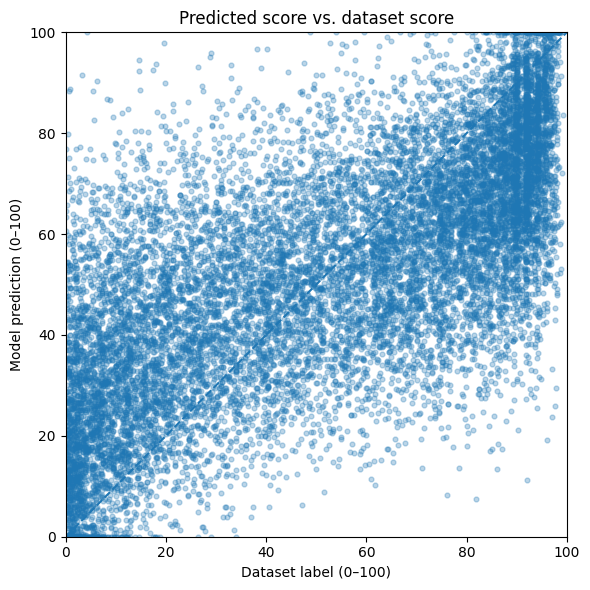

In [42]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, test_predictions, alpha=0.3, s=12)
plt.plot([0, 100], [0, 100], linestyle="--")
plt.title("Predicted score vs. dataset score")
plt.xlabel("Dataset label (0–100)")
plt.ylabel("Model prediction (0–100)")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

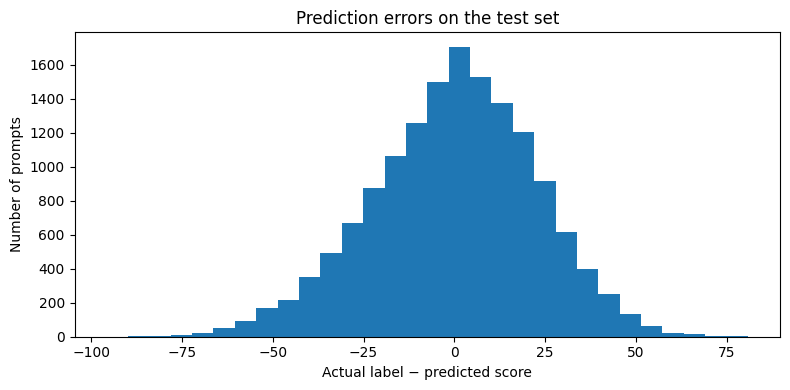

In [43]:
residuals = y_test - test_predictions
plt.figure(figsize=(8, 4))
plt.hist(residuals, bins=30)
plt.title("Prediction errors on the test set")
plt.xlabel("Actual label − predicted score")
plt.ylabel("Number of prompts")
plt.tight_layout()
plt.show()

### Evaluation notes

1. If the model beats the mean baseline, it is learning useful patterns from the chosen dataset. If it does not, inspect the data/features and try a different model or more training examples.
2. A random held-out split can still contain prompts similar to training examples. A stronger future evaluation would use a separate human-rated test set or split by prompt source/domain.
3. Because the labels were produced by model evaluators, our score estimates similarity to those evaluators' judgments. A human review is still needed before presenting this as a reliable real-world quality scale.

## 11. Build explainable prompt checks

These checks do not replace the trained model. They create plain-language feedback from visible features. Every suggestion is phrased as something to consider, because not every good prompt needs every element.

In [12]:
def inspect_prompt(text):
    text = str(text).strip()
    lower = text.lower()
    words = re.findall(r"\b[\w'-]+\b", lower)

    checks = {
        "clear_action": any(word in lower for word in [
            "write", "create", "explain", "summarize", "compare", "analyze", "analyse",
            "generate", "design", "build", "calculate", "classify", "translate", "debug",
            "recommend", "plan", "review", "evaluate", "teach"
        ]),
        "context": any(phrase in lower for phrase in [
            "context", "background", "based on", "given the following", "here is", "input:"
        ]),
        "constraints": any(phrase in lower for phrase in [
            "must", "should", "do not", "don't", "avoid", "limit", "maximum", "minimum", "within", "only"
        ]),
        "output_format": any(phrase in lower for phrase in [
            "json", "markdown", "table", "bullet points", "format", "csv", "headings", "list of"
        ]),
        "audience": any(phrase in lower for phrase in [
            "audience", "for beginners", "for experts", "for a student", "for children", "for managers"
        ]),
        "examples": any(phrase in lower for phrase in [
            "example", "for example", "sample", "illustration", "e.g."
        ]),
        "role": any(phrase in lower for phrase in [
            "you are", "act as", "as an expert", "as a professional"
        ]),
    }
    return {
        "word_count": len(words),
        "checks": checks,
    }


def score_band(score):
    if score < 40:
        return "Needs substantial clarification"
    if score < 60:
        return "Basic idea present; add detail where needed"
    if score < 80:
        return "Fairly well structured; refine weak areas"
    return "Well structured by this model; still test the output"


def make_feedback(text, checks, word_count):
    feedback = []
    if word_count < 8:
        feedback.append("The prompt is very short. Add enough detail to make the intended task unambiguous, if needed.")
    if not checks["clear_action"]:
        feedback.append("State the action clearly (for example: explain, compare, design, summarize, or debug).")
    if not checks["context"]:
        feedback.append("Consider adding relevant background, input data, or the situation the answer should use.")
    if not checks["constraints"]:
        feedback.append("Add important boundaries such as scope, length, tools to use/avoid, or assumptions — only if they matter.")
    if not checks["output_format"]:
        feedback.append("Specify the answer format if you care about the shape of the result (steps, table, bullets, JSON, etc.).")
    if not checks["audience"]:
        feedback.append("Name the intended audience or knowledge level when it affects how the answer should be explained.")
    if not checks["examples"]:
        feedback.append("For a precise or repetitive task, consider giving a small example of the expected result.")
    if not feedback:
        feedback.append("The basic structural checks look good. Test the prompt with real tasks and revise based on the answer quality.")
    return feedback


def build_improved_prompt(original, checks):
    """Create a structured draft while preserving the user's original task."""
    parts = [
        "You are a helpful assistant. Complete the task accurately and directly.",
        "## Task\n" + original.strip(),
    ]

    if not checks["context"]:
        parts.append(
            "## Context\n"
            "- Relevant background or input: [add details or data if needed]\n"
            "- If essential information is missing, ask a concise clarifying question instead of inventing facts."
        )
    if not checks["audience"]:
        parts.append("## Audience\n- Intended reader: [state the reader's level or audience, if relevant]")
    if not checks["constraints"]:
        parts.append(
            "## Requirements and constraints\n"
            "- Stay focused on the task.\n"
            "- Respect any limits, assumptions, or exclusions provided by the user.\n"
            "- State important assumptions; do not make up facts or sources."
        )
    if not checks["output_format"]:
        parts.append(
            "## Output format\n"
            "- Give the direct answer first.\n"
            "- Use numbered steps or headings for multi-part answers.\n"
            "- Include examples or a table only when they help."
        )
    if not checks["examples"]:
        parts.append("## Example (optional)\n- Add a short example of the expected output if consistency is important.")

    parts.append(
        "## Final self-check\n"
        "Before answering, verify that the response addresses the task, follows the stated constraints, "
        "uses the requested format, and clearly flags any uncertainty."
    )
    return "\n\n".join(parts)

## 12. Put the whole analyzer together

The displayed score is the model's prediction. The suggestions are rule-based. The rewritten prompt is a scaffolded draft: it keeps the original task and adds missing sections/placeholders. It does not understand every domain nuance, so read and edit the result before using it.

In [13]:
def analyze_prompt(prompt, show_output=True):
    prompt = str(prompt).strip()
    if len(prompt) < 2:
        raise ValueError("Please enter a prompt with at least a couple of characters.")

    predicted_score = float(np.clip(prompt_model.predict([prompt])[0], 0, 100))
    inspected = inspect_prompt(prompt)
    feedback = make_feedback(prompt, inspected["checks"], inspected["word_count"])
    improved = build_improved_prompt(prompt, inspected["checks"])
    improved_score = float(np.clip(prompt_model.predict([improved])[0], 0, 100))

    result = {
        "score": round(predicted_score, 1),
        "band": score_band(predicted_score),
        "word_count": inspected["word_count"],
        "checks": inspected["checks"],
        "feedback": feedback,
        "improved_prompt": improved,
        "improved_prompt_score": round(improved_score, 1),
    }

    if show_output:
        display(Markdown(f"## Predicted prompt score: **{result['score']}/100**"))
        display(Markdown(f"**Interpretation:** {result['band']}"))
        display(Markdown(f"**Prompt length:** {result['word_count']} words"))

        check_table = pd.DataFrame([
            {"Dimension/check": key.replace("_", " ").title(), "Detected": "Yes" if value else "Not detected"}
            for key, value in result["checks"].items()
        ])
        display(check_table)

        display(Markdown("### Suggestions"))
        for item in feedback:
            display(Markdown(f"- {item}"))

        display(Markdown("### Improved prompt draft"))
        display(Markdown("```text\n" + improved + "\n```"))
        display(Markdown(
            f"**Model's score for the draft:** {result['improved_prompt_score']}/100. "
            "This is a prediction, not proof that the rewritten prompt will perform better."
        ))

    return result

## 13. Test it on an example

First try the same example below. Then edit the text and run the cell again. The point is to observe which checks fire and whether the revised version is actually more useful for the task.

In [14]:
example_prompt = "Explain machine learning."
example_result = analyze_prompt(example_prompt)

## Predicted prompt score: **41.6/100**

**Interpretation:** Basic idea present; add detail where needed

**Prompt length:** 3 words

,Dimension/check,Detected
0,Clear Action,Yes
1,Context,Not detected
2,Constraints,Not detected
3,Output Format,Not detected
4,Audience,Not detected
5,Examples,Not detected
6,Role,Not detected


### Suggestions

...

- Name the intended audience or knowledge level when it affects how the answer should be explained.

- For a precise or repetitive task, consider giving a small example of the expected result.

### Improved prompt draft

```text
You are a helpful assistant. Complete the task accurately and directly.

## Task
Explain machine learning.

## Context
- Relevant background or input: [add details or data if needed]
- If essential information is missing, ask a concise clarifying question instead of inventing facts.

## Audience
- Intended reader: [state the reader's level or audience, if relevant]

## Requirements and constraints
- Stay focused on the task.
- Respect any limits, assumptions, or exclusions provided by the user.
- State important assumptions; do not make up facts or sources.

## Output format
- Give the direct answer first.
- Use numbered steps or headings for multi-part answers.
- Include examples or a table only when they help.

## Example (optional)
- Add a short example of the expected output if consistency is important.

## Final self-check
Before answering, verify that the response addresses the task, follows the stated constraints, uses the requested format, and clearly flags any uncertainty.
```

**Model's score for the draft:** 82.0/100. This is a prediction, not proof that the rewritten prompt will perform better.

## 14. Try your own prompt

Paste a real prompt you might use for study, coding, research, or another task. Try a vague version first, then a more specific version and compare the suggestions. Avoid pasting passwords, private data, or confidential information.

In [15]:
my_prompt = input("Paste your prompt here: ")
my_result = analyze_prompt(my_prompt)

Paste your prompt here: hey buddy help me to make ML prompt quality analyser


## Predicted prompt score: **14.7/100**

**Interpretation:** Needs substantial clarification

**Prompt length:** 10 words

,Dimension/check,Detected
0,Clear Action,Yes
1,Context,Not detected
2,Constraints,Not detected
3,Output Format,Not detected
4,Audience,Not detected
5,Examples,Not detected
6,Role,Not detected


...

- Name the intended audience or knowledge level when it affects how the answer should be explained.

- For a precise or repetitive task, consider giving a small example of the expected result.

### Improved prompt draft

```text
You are a helpful assistant. Complete the task accurately and directly.

## Task
hey buddy help me to make ML prompt quality analyser

## Context
- Relevant background or input: [add details or data if needed]
- If essential information is missing, ask a concise clarifying question instead of inventing facts.

## Audience
- Intended reader: [state the reader's level or audience, if relevant]

## Requirements and constraints
- Stay focused on the task.
- Respect any limits, assumptions, or exclusions provided by the user.
- State important assumptions; do not make up facts or sources.

## Output format
- Give the direct answer first.
- Use numbered steps or headings for multi-part answers.
- Include examples or a table only when they help.

## Example (optional)
- Add a short example of the expected output if consistency is important.

## Final self-check
Before answering, verify that the response addresses the task, follows the stated constraints, uses the requested format, and clearly flags any uncertainty.
```

**Model's score for the draft:** 75.6/100. This is a prediction, not proof that the rewritten prompt will perform better.

## 15. Save the trained model

This saves the whole preprocessing + regression pipeline as one file, so the exact vectorizers and feature logic travel with the model. Only load model files you created or otherwise trust. In Colab, use the download cell to save a copy to your computer.

In [16]:
import joblib

MODEL_PATH = "prompt_quality_analyzer.joblib"
joblib.dump(prompt_model, MODEL_PATH)
print(f"Saved model to: {MODEL_PATH}")

Saved model to: prompt_quality_analyzer.joblib


In [19]:
import os
import joblib
from pathlib import Path

# Find the saved model
candidates = [
    Path("prompt_quality_analyzer.joblib"),
    Path("/content/prompt_quality_analyzer.joblib")
]

model_path = next(
    (p for p in candidates if p.exists()),
    None
)

# Upload the file if it is not found
if model_path is None:
    from google.colab import files
    uploaded = files.upload()
    model_path = Path(next(iter(uploaded)))

# Load the saved model
model = joblib.load(model_path)

print("✅ Model loaded successfully!")
print("Model type:", type(model))

✅ Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>


In [20]:
print("Model available:", "model" in globals())
print("X_test available:", "X_test" in globals())
print("y_test available:", "y_test" in globals())

Model available: True
X_test available: True
y_test available: True


In [21]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Use the existing held-out test set
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("-" * 35)
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

MODEL EVALUATION
-----------------------------------
MAE  : 18.9951
RMSE : 23.6626
R²   : 0.4621


In [22]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Confirm the original training labels are available
if "y_train" not in globals():
    raise NameError(
        "y_train not found. Run your original train-test split cell first."
    )

# Predictions from the trained ML model
model_predictions = np.asarray(
    model.predict(X_test)
).reshape(-1)

# Baseline: always predict the training-set mean
train_mean = np.asarray(y_train).mean()

baseline_predictions = np.full(
    len(y_test), train_mean, dtype=float
)

# Compare using the same held-out test set
def evaluate(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    }

comparison = pd.DataFrame([
    evaluate("Ridge Regression", y_test, model_predictions),
    evaluate("Mean baseline", y_test, baseline_predictions)
])

display(comparison.round(4))

,Model,MAE,RMSE,R2
0,Ridge Regression,18.9951,23.6626,0.4621
1,Mean baseline,28.9153,32.2656,-0.0001


In [23]:
import re
import numpy as np

def analyze_prompt(prompt):
    if not isinstance(prompt, str) or not prompt.strip():
        raise ValueError("Please enter a non-empty prompt.")

    prompt = prompt.strip()
    text = prompt.lower()
    words = re.findall(r"\b[\w'-]+\b", text)

    # 1. Predict quality score using the trained ML pipeline
    score = float(np.clip(model.predict([prompt])[0], 0, 100))

    # 2. Identify possible weaknesses using transparent rules
    suggestions = []
    additions = []

    if len(words) < 12:
        suggestions.append(
            "The prompt is short. Clarify the exact task and expected result."
        )
        additions.append(
            "Clearly state the task and the expected result."
        )

    if not any(x in text for x in [
        "context", "background", "given", "based on"
    ]):
        suggestions.append(
            "Add relevant background or context."
        )
        additions.append(
            "Include the relevant background and context."
        )

    if not any(x in text for x in [
        "audience", "beginner", "student", "expert",
        "manager", "for children"
    ]):
        suggestions.append(
            "Specify the intended audience or knowledge level."
        )
        additions.append(
            "Specify the intended audience and appropriate level of detail."
        )

    if not any(x in text for x in [
        "format", "table", "bullet points", "json",
        "markdown", "numbered list", "headings"
    ]):
        suggestions.append(
            "Specify the desired output format."
        )
        additions.append(
            "Organize the answer with clear headings or numbered steps."
        )

    if not any(x in text for x in [
        "must", "should", "avoid", "limit",
        "maximum", "minimum", "within", "exactly"
    ]):
        suggestions.append(
            "Add relevant constraints or requirements."
        )
        additions.append(
            "State any important constraints, requirements, or length limits."
        )

    if not any(x in text for x in [
        "example", "for example", "sample", "e.g."
    ]):
        suggestions.append(
            "Request an example if it would help explain the task."
        )
        additions.append(
            "Include a relevant example where useful."
        )

    # 3. Create a transparent, template-based improvement draft
    if additions:
        improved_prompt = (
            prompt
            + "\n\nAdditional guidance:\n"
            + "\n".join(f"- {item}" for item in additions)
            + "\n- State assumptions clearly and ask for clarification "
              "if essential information is missing."
        )
    else:
        improved_prompt = (
            prompt
            + "\n\nAdditional guidance:\n"
            + "- State assumptions clearly and ask for clarification "
              "if essential information is missing."
        )

    # 4. Display all results
    if score < 40:
        category = "Needs improvement"
    elif score < 70:
        category = "Fair"
    else:
        category = "Good"

    print("=" * 48)
    print("PROMPT QUALITY ANALYZER")
    print("=" * 48)
    print(f"Predicted score: {score:.2f}/100")
    print(f"Demo category: {category}")
    print("\nSUGGESTIONS")

    if suggestions:
        for i, suggestion in enumerate(suggestions, 1):
            print(f"{i}. {suggestion}")
    else:
        print("No obvious weaknesses detected by these rules.")

    print("\nIMPROVED PROMPT DRAFT")
    print(improved_prompt)

    print("\nNote: The score is an ML prediction. "
          "Suggestions use rule-based checks.")

    return {
        "score": score,
        "category": category,
        "suggestions": suggestions,
        "improved_prompt": improved_prompt
    }


# Try it with a real example
result = analyze_prompt("Explain machine learning.")

PROMPT QUALITY ANALYZER
Predicted score: 41.56/100
Demo category: Fair

SUGGESTIONS
1. The prompt is short. Clarify the exact task and expected result.
2. Add relevant background or context.
3. Specify the intended audience or knowledge level.
4. Specify the desired output format.
5. Add relevant constraints or requirements.
6. Request an example if it would help explain the task.

IMPROVED PROMPT DRAFT
Explain machine learning.

Additional guidance:
- Clearly state the task and the expected result.
- Include the relevant background and context.
- Specify the intended audience and appropriate level of detail.
- Organize the answer with clear headings or numbered steps.
- State any important constraints, requirements, or length limits.
- Include a relevant example where useful.
- State assumptions clearly and ask for clarification if essential information is missing.

Note: The score is an ML prediction. Suggestions use rule-based checks.


In [24]:
import numpy as np
import pandas as pd

original_prompt = "Explain machine learning."

improved_prompt = """
You are a friendly machine learning instructor teaching a
second-year B.Tech CSE student. Explain machine learning
in simple language. Start with a clear definition, explain
supervised, unsupervised and reinforcement learning, and give
one practical example of each. Compare these approaches in
a table and finish with a concise summary. Avoid unexplained
technical jargon and keep the answer under 600 words.
"""

original_score = float(
    np.clip(model.predict([original_prompt])[0], 0, 100)
)

improved_score = float(
    np.clip(model.predict([improved_prompt])[0], 0, 100)
)

comparison = pd.DataFrame([
    {
        "Version": "Original prompt",
        "Predicted score": round(original_score, 2)
    },
    {
        "Version": "Improved prompt",
        "Predicted score": round(improved_score, 2)
    }
])

display(comparison)

print(
    "Predicted score change:",
    round(improved_score - original_score, 2),
    "points"
)

,Version,Predicted score
0,Original prompt,41.56
1,Improved prompt,100.00


Predicted score change: 58.44 points


In [25]:
import numpy as np

raw_original = float(model.predict([original_prompt])[0])
raw_improved = float(model.predict([improved_prompt])[0])

print("RAW MODEL PREDICTIONS")
print("-" * 35)

print(f"Original prompt: {raw_original:.4f}")
print(f"Improved prompt: {raw_improved:.4f}")

print("\nDISPLAY SCORES (capped to 0–100)")
print(f"Original: {np.clip(raw_original, 0, 100):.2f}")
print(f"Improved: {np.clip(raw_improved, 0, 100):.2f}")

RAW MODEL PREDICTIONS
-----------------------------------
Original prompt: 41.5614
Improved prompt: 107.8682

DISPLAY SCORES (capped to 0–100)
Original: 41.56
Improved: 100.00


In [26]:
import numpy as np

targets = np.asarray(y_train, dtype=float).ravel()

print("Training target statistics")
print("-" * 35)
print("Minimum:", targets.min())
print("Maximum:", targets.max())
print("Mean:", round(targets.mean(), 2))
print("Median:", round(np.median(targets), 2))

print("\nTarget percentiles:")
for p in [25, 50, 75, 90, 95, 99]:
    print(f"{p}th percentile:", round(np.percentile(targets, p), 2))

Training target statistics
-----------------------------------
Minimum: 0.043
Maximum: 99.18
Mean: 52.02
Median: 55.99

Target percentiles:
25th percentile: 20.1
50th percentile: 55.99
75th percentile: 83.56
90th percentile: 91.97
95th percentile: 94.24
99th percentile: 96.99


## 16. Summary and future improvements

### Current prototype
- Loads an open prompt-quality dataset.
- Performs cleaning and exploratory data analysis.
- Uses word and character TF-IDF plus structural features.
- Trains a Ridge regression model and compares it with a mean baseline.
- Reports MAE, RMSE, and R² on held-out data.
- Gives explainable suggestions and creates a structured prompt draft.

### What could make the next version stronger
1. Collect human ratings from several reviewers using a fixed rubric (clarity, context, specificity, constraints, output format, and examples).
2. Evaluate on a new dataset/domain that was not used during training.
3. Check consistency across languages and task types; this notebook's selected data is English.
4. Compare Ridge with models such as `TfidfVectorizer + LinearSVR` or a sentence-embedding regressor, using the same split and metrics.
5. Ask users to rate whether suggestions helped, and revise the rubric based on this feedback.

### Honest limitation statement for a demo
This is a proof-of-concept ML analyzer, not a guarantee of response quality. The predicted score approximates dataset labels. The rubric checks are heuristic signals; some may be irrelevant to a particular task. The improved prompt is a structured draft and should be reviewed by a human.

## 17. Evaluation / viva practice

**1. What is the problem you're solving?**  
A prompt may omit task details, relevant context, constraints, audience, examples, or expected output structure. The tool estimates quality and suggests improvements before an LLM is used.

**2. Why is this a machine learning problem?**  
The dataset provides prompt text with quality labels. We train a supervised regression model to learn a mapping from text/features to a continuous score.

**3. Why regression and not classification?**  
The target is a continuous 0–100 score. We could also group the scores into classes, but regression preserves more detail.

**4. What are TF-IDF features?**  
They represent how important words or short phrases are within a document relative to the corpus. We use word n-grams and character n-grams.

**5. Why add structural features when TF-IDF already exists?**  
TF-IDF captures language patterns; structural features explicitly represent signals such as word count, context markers, output-format markers, and constraints.

**6. Why Ridge regression?**  
It is a regularized linear model that works well with high-dimensional sparse text features and is relatively lightweight to train.

**7. Why do you use a baseline?**  
A model is only useful if it performs better than a simple reference. The mean baseline predicts the same training-set average for every test prompt.

**8. Explain MAE, RMSE, and R².**  
MAE is the average absolute error in points. RMSE gives more weight to larger errors. R² compares predictions with a constant-mean predictor; higher is generally better.

**9. Are the labels human ground truth?**  
No. The chosen dataset's normalized quality score is based on assessments from multiple language models. It is a proxy label, so model performance should be interpreted with that limitation.

**10. Is the score guaranteed to be correct?**  
No. It is an estimate learned from the data. A structured prompt can still be wrong for its task, and a good short prompt can be unfairly undervalued.

**11. Is the improved prompt generated by another ML model?**  
No. In this version, the score is ML-based but the feedback and improved-prompt scaffold are rule-based. This keeps the demo free of API keys and makes the suggestions easy to explain.

**12. What would you do next?**  
Collect human-rated prompts, test on a separate domain, compare additional models, assess language fairness, and evaluate whether users find the suggestions useful.